# Investigating if machine learning models can predict EV battery state of health and observing the adaptability of the models in different temperature extremes

ENGG2112 group project.

Models that estimate battery capacity from voltage readings are often trained at a single temperature, but measuring capacity at a new temperature requires time-consuming discharge testing. In this notebook we train eight regression models to estimate an unseen battery cell's next-discharge capacity, in ampere-hours (Ah), from the voltage settling after charging. We then test how well models trained at 25 °C transfer to 35 °C and 45 °C, and how much labelled data from the target temperature they need.

Data: Zenodo record 6405084, Dataset 1 (Zhu et al.), with 66 nickel–cobalt–aluminium oxide (NCA) cells (LG INR18650-35E, 3.5 Ah) at 25 °C (35 cells), 35 °C (3 cells) and 45 °C (28 cells). State of Health (SoH) is calculated against a reference capacity of 3.5 Ah. Our target is a mean absolute error (MAE) of at most 0.05 Ah (about 1.4 % SoH), with at least a 20 % improvement over a mean baseline.

Steps:
1. Data loading
2. Cleaning and preprocessing
3. Feature engineering
4. Model training
5. Evaluation and results
6. Temperature transfer
7. Feature importance

The results in our report come from our full study scripts in `full_study_code/`, which use nested leave-one-cell-out validation with setting selection, PyTorch MLPs with five seeds, all eight models at seven donor-data budgets, and SHAP. This notebook follows the same data, features and cell-level tests in a simpler form: fixed model settings based on the report's Table 2 (with 100 trees instead of 300 for the forests), scikit-learn models, one seed, and permutation importance instead of SHAP. Its numbers are therefore close to, but not exactly the same as, the report.

In [1]:
# import libraries and models, and set the dataset path and project settings
import os
import re
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

warnings.filterwarnings('ignore')     # hides MLP convergence warnings

RAW_DIR = 'Dataset_1_NCA_battery'     # raw CY*.csv files (download from Zenodo, see README)
NOMINAL_AH = 3.5                      # rated capacity of the cell
TARGET_AH = 0.05                      # success target: MAE <= 0.05 Ah (about 1.4 % SoH)
REBUILD_FEATURES = False              # True = rebuild the feature table from all raw files

## 1. Data loading

Each raw CSV file is one battery cell, cycled until it wore out. The file name gives the test conditions, for example `CY25-1_1-#3` is 25 °C, 1C charge, 1C discharge, cell 3. Each row is one time sample of time, cell voltage, measured current, the tester's control setting, the discharge capacity counter and the cycle number.

This section uses the example file `Dataset_1_NCA_battery/CY25-1_1-#3.csv`, which is included in the repository.

In [2]:
# read one raw file and look at its rows (time samples) and number of cycles
example_file = os.path.join(RAW_DIR, 'CY25-1_1-#3.csv')
raw = pd.read_csv(example_file)
print('Rows (time samples):', len(raw))
print('Cycles:', raw['cycle number'].nunique())
raw.head()

Rows (time samples): 25926
Cycles: 29


,time/s,control/V/mA,Ecell/V,<I>/mA,Q discharge/mA.h,Q charge/mA.h,control/V,control/mA,cycle number
0,0.000,3500.0,3.190572,0.058273,0.0,0.001944,0.0,3500.0,1.0
1,0.014,3500.0,3.196046,3500.266540,0.0,0.015556,0.0,3500.0,1.0
2,0.070,3500.0,3.201126,3501.152395,0.0,0.070018,0.0,3500.0,1.0
3,0.214,3500.0,3.206167,3501.234799,0.0,0.210068,0.0,3500.0,1.0
4,0.440,3500.0,3.211207,3501.412094,0.0,0.429879,0.0,3500.0,1.0


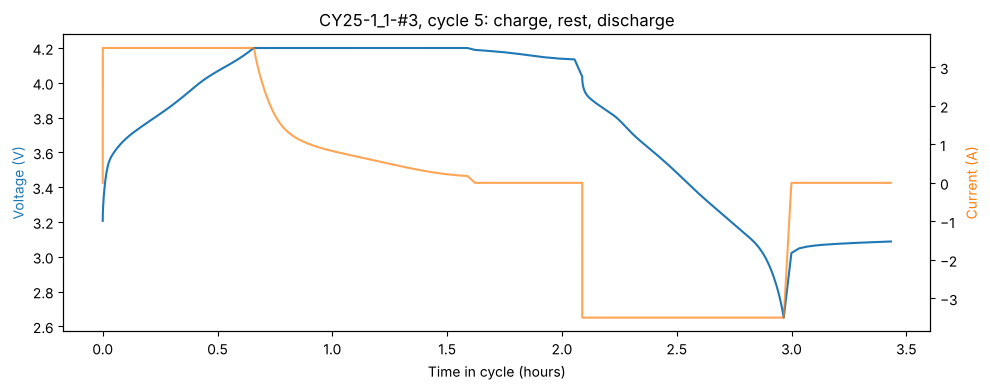

In [3]:
# One cycle: charge -> rest -> discharge
cycle = raw[raw['cycle number'] == 5] # here we just filter rows based on only one cycle (5th cycle) from cycle column
t_hours = (cycle['time/s'] - cycle['time/s'].iloc[0]) / 3600 # since 5th cycle does not start at 0, we make it start at 0 to avoid confusion and convert time from seconds to hours

plt.figure(figsize=(10, 4))

plt.plot(t_hours, cycle['Ecell/V'], color='tab:blue')
plt.xlabel('Time in cycle (hours)')
plt.ylabel('Voltage (V)', color='tab:blue')

plt.twinx()                      # second y-axis on the right
plt.plot(t_hours, cycle['<I>/mA'] / 1000, color='tab:orange', alpha=0.7)
plt.ylabel('Current (A)', color='tab:orange')

plt.title('CY25-1_1-#3, cycle 5: charge, rest, discharge')
plt.tight_layout()
plt.show()

Each cycle is a charge, a rest with zero current, and a discharge. After a full charge the cell rests and its voltage drops slowly, known as relaxation. Our inputs come from this rest, and the next discharge supplies the known capacity to predict.

## 2. Cleaning and preprocessing, and 3. Feature engineering

The extractor takes the first 14 consecutive voltage measurements during rest after charging and before discharge. They must exceed 4 V, with the measured current being no greater than 1 mA in magnitude. The next discharge supplies the known capacity to predict.

The 24 inputs are these 14 voltages with seven summaries of their level, spread, shape and change over time (mean, variance, maximum, skewness, excess kurtosis, drop and slope), as well as temperature plus planned charge and discharge rates. Cell identity, cycle number and later discharge measurements are excluded so that the model cannot use information from the discharge that it is trying to predict.

Cleaning rules:
- cycles without a qualifying relaxation block are rejected
- cycles outside the 2.5–3.5 Ah range are removed (about 71–100 % SoH)
- each cell needs at least ten cycles

In [4]:
# Feature engineering
# Each raw file is one battery cell. Its test conditions are only in the file name, e.g.
# CY25-05_1-#3 = 25 °C, 0.5C charge, 1C discharge, cell 3, so parse_filename reads them from the name.
# extract_cycle turns one cycle into one row: it finds where the discharge starts, takes the first
# 14 voltage readings of the rest period after charging (tester off, current about 0, above 4 V),
# calculates 7 statistics of those readings, and records the capacity delivered in the discharge
# (the target). Cycles without a discharge or a clean 14-point rest are skipped (None).
# extract_cell runs extract_cycle on every cycle of one file and returns a table, one row per cycle.

RATES = {'025': 0.25, '05': 0.5, '1': 1.0}


def parse_filename(name):
    name = name.replace('CY', '')               # '25-05_1-#3'
    temp_text, rest = name.split('-', 1)        # '25', '05_1-#3'
    charge_text, rest = rest.split('_')         # '05', '1-#3'
    discharge_text = rest.split('-')[0]         # '1'
    return int(temp_text), RATES[charge_text], RATES[discharge_text]


def extract_cycle(g):
    time = g['time/s'].tolist()
    control = g['control/V/mA'].tolist()
    voltage = g['Ecell/V'].tolist()
    current = g['<I>/mA'].tolist()
    q_discharge = g['Q discharge/mA.h'].tolist()

    # 1. first row of the discharge
    d = -1
    for i in range(len(time)):
        if control[i] < -1:
            d = i
            break
    if d == -1:
        return None

    # 2. first 14 rest rows in a row, after the cell has been charged
    start = -1
    charged = False
    count = 0
    for i in range(d):
        is_rest = abs(control[i]) < 1e-8 and abs(current[i]) <= 1 and voltage[i] > 4.0
        if is_rest and charged:
            count = count + 1
            if count == 14:
                start = i - 13
                break
        else:
            count = 0
        if current[i] > 100:
            charged = True
    if start == -1:
        return None

    # 3. the 14 relaxation voltages and their times
    v = voltage[start:start + 14]
    t = time[start:start + 14]

    # 4. statistics
    mean = sum(v) / 14
    m2 = 0
    m3 = 0
    m4 = 0
    for x in v:
        m2 = m2 + (x - mean) ** 2 / 14
        m3 = m3 + (x - mean) ** 3 / 14
        m4 = m4 + (x - mean) ** 4 / 14

    features = {}
    features['relaxation_mean_v'] = mean
    features['relaxation_variance_v2'] = m2
    features['relaxation_max_v'] = max(v)
    features['relaxation_skewness'] = m3 / m2 ** 1.5
    features['relaxation_excess_kurtosis'] = m4 / m2 ** 2 - 3
    features['relaxation_drop_v'] = v[0] - v[13]
    features['relaxation_slope_v_per_s'] = (v[13] - v[0]) / (t[13] - t[0])
    for j in range(14):
        number = str(j + 1)
        if j + 1 < 10:
            number = '0' + number
        features['relaxation_v_' + number] = v[j]

    # 5. target: capacity delivered in the discharge, mAh -> Ah
    features['capacity_ah'] = max(q_discharge[d:]) / 1000
    return features


def extract_cell(path):
    cell = os.path.basename(path).replace('.csv', '')
    temp, charge_rate, discharge_rate = parse_filename(cell)
    raw = pd.read_csv(path)

    rows = []
    for cycle_no, g in raw.groupby('cycle number'):
        features = extract_cycle(g)
        if features is None:
            continue
        features['ambient_c'] = temp
        features['planned_charge_c_rate'] = charge_rate
        features['planned_discharge_c_rate'] = discharge_rate
        features['temperature_c'] = temp
        features['cell'] = cell
        features['sequence'] = cycle_no
        rows.append(features)
    return pd.DataFrame(rows)

In [5]:
# run the feature extraction on the example cell: one row per usable cycle
one_cell = extract_cell(example_file)
print(len(one_cell), 'of', raw['cycle number'].nunique(), 'cycles usable')
one_cell.head()

29 of 29 cycles usable


,relaxation_mean_v,relaxation_variance_v2,relaxation_max_v,relaxation_skewness,relaxation_excess_kurtosis,relaxation_drop_v,relaxation_slope_v_per_s,relaxation_v_01,relaxation_v_02,relaxation_v_03,...,relaxation_v_12,relaxation_v_13,relaxation_v_14,capacity_ah,ambient_c,planned_charge_c_rate,planned_discharge_c_rate,temperature_c,cell,sequence
0,4.169435,0.000273,4.190542,-0.439118,-1.147916,0.051233,-0.000033,4.190542,4.188337,4.186683,...,4.149508,4.144035,4.139309,3.094879,25,1.0,1.0,25,CY25-1_1-#3,1.0
1,4.166599,0.000317,4.190463,-0.307644,-1.297254,0.053872,-0.000035,4.190463,4.187746,4.185580,...,4.144743,4.140058,4.136592,3.083021,25,1.0,1.0,25,CY25-1_1-#3,2.0
2,4.163761,0.000357,4.189951,-0.167360,-1.418000,0.055801,-0.000036,4.189951,4.187273,4.184753,...,4.140845,4.137143,4.134150,3.077399,25,1.0,1.0,25,CY25-1_1-#3,3.0
3,4.162282,0.000354,4.189597,-0.068462,-1.444592,0.055525,-0.000036,4.189597,4.186447,4.183572,...,4.139782,4.136749,4.134072,3.073393,25,1.0,1.0,25,CY25-1_1-#3,4.0
4,4.161241,0.000346,4.189164,0.014084,-1.452829,0.054620,-0.000035,4.189164,4.185974,4.182666,...,4.139191,4.136671,4.134544,3.071195,25,1.0,1.0,25,CY25-1_1-#3,5.0


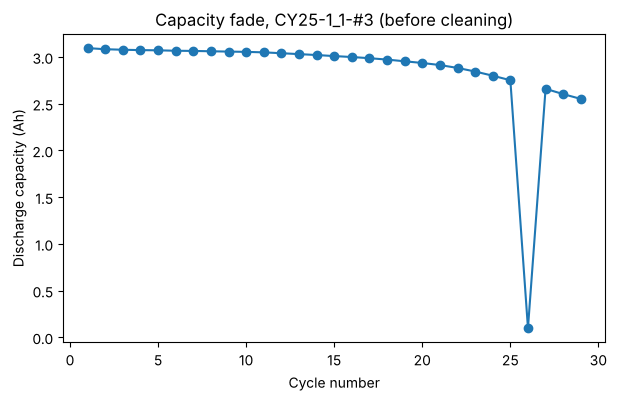

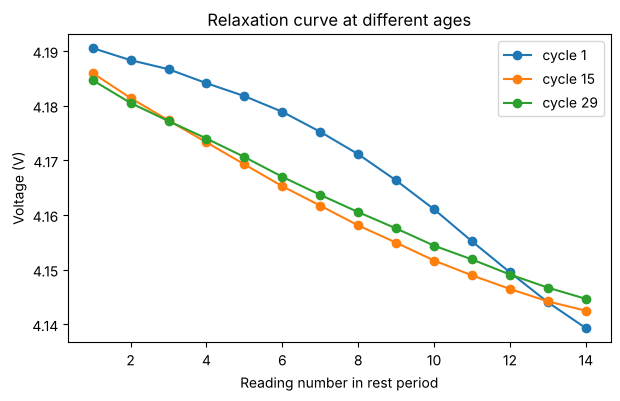

In [6]:
# two exploratory plots: capacity against cycle number, and the 14 rest voltages at three ages

# Plot 1: capacity fade of the example cell
plt.figure(figsize=(7, 4))
plt.plot(one_cell['sequence'], one_cell['capacity_ah'], 'o-')
plt.xlabel('Cycle number')
plt.ylabel('Discharge capacity (Ah)')
plt.title('Capacity fade, CY25-1_1-#3 (before cleaning)')
plt.show()

# Plot 2: the 14 rest voltages for the first, middle and last cycle
voltage_columns = ['relaxation_v_01', 'relaxation_v_02', 'relaxation_v_03', 'relaxation_v_04',
                   'relaxation_v_05', 'relaxation_v_06', 'relaxation_v_07', 'relaxation_v_08',
                   'relaxation_v_09', 'relaxation_v_10', 'relaxation_v_11', 'relaxation_v_12',
                   'relaxation_v_13', 'relaxation_v_14']

first = one_cell.iloc[0]
middle = one_cell.iloc[14]
last = one_cell.iloc[28]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 15), first[voltage_columns], 'o-', label='cycle 1')
plt.plot(range(1, 15), middle[voltage_columns], 'o-', label='cycle 15')
plt.plot(range(1, 15), last[voltage_columns], 'o-', label='cycle 29')
plt.xlabel('Reading number in rest period')
plt.ylabel('Voltage (V)')
plt.title('Relaxation curve at different ages')
plt.legend()
plt.show()

The drop to about 0.1 Ah at cycle 26 is a bad cycle, not real ageing, and the 2.5–3.5 Ah filter removes it. The relaxation curve changes as the cell ages, which is the information the models learn from.

Dataset 1 contained 66 cells with 22,914 cycles. The extraction rejected 405 cycles without a qualifying relaxation block and three with decreasing time. Of the 22,506 valid cycles, 267 lay outside the 2.5–3.5 Ah range, leaving 22,239. All 66 cells passed the minimum ten cycle requirement.

By default the notebook loads this prepared feature table (`data/features.csv`) from our full study. Setting `REBUILD_FEATURES = True` rebuilds it from all 66 raw files (download from Zenodo) and saves it as `data/features_rebuilt.csv`. The check below confirms that our extraction code reproduces the prepared table.

In [7]:
# build the feature table from all raw files, or load the prepared table
if REBUILD_FEATURES:
    tables = []
    for f in sorted(os.listdir(RAW_DIR)):
        if f.startswith('CY') and f.endswith('.csv'):
            cell_table = extract_cell(RAW_DIR + '/' + f)

            # cleaning: keep cycles with capacity between 2.5 and 3.5 Ah
            cell_table = cell_table[(cell_table['capacity_ah'] >= 2.5) & (cell_table['capacity_ah'] <= 3.5)]

            # cleaning: keep the cell only if it has at least 10 cycles
            if len(cell_table) >= 10:
                tables.append(cell_table)

    data = pd.concat(tables, ignore_index=True)     # stack all cells into one table
    data.to_csv('data/features_rebuilt.csv', index=False)
else:
    data = pd.read_csv('data/features.csv')

FEATURES = json.load(open('data/feature_names.json'))
print('Cycles:', len(data), '| Cells:', data['cell'].nunique(), '| Inputs:', len(FEATURES))

Cycles: 22239 | Cells: 66 | Inputs: 24


In [8]:
# reproducibility check: our extraction gives the same values as the prepared feature table
original = pd.read_csv('data/features.csv')
check = one_cell.merge(original, on=['cell', 'sequence'], suffixes=('_ours', '_table'))

for col in ['relaxation_v_01', 'relaxation_skewness', 'capacity_ah']:
    difference = (check[col + '_ours'] - check[col + '_table']).abs().max()
    print(col, 'max difference =', difference)

relaxation_v_01 max difference = 0.0
relaxation_skewness max difference = 2.1860291354869332e-13
capacity_ah max difference = 4.440892098500626e-16


Table 1 (report): usable data at each temperature. 35 °C has only three cells, so it is the least certain temperature in our results.

In [9]:
# Report Table 1: usable data per temperature
for temp in [25, 35, 45]:
    group = data[data['temperature_c'] == temp]
    print(temp, '°C:', group['cell'].nunique(), 'cells,', len(group), 'cycles')

25 °C: 35 cells, 5352 cycles
35 °C: 3 cells, 1112 cycles
45 °C: 28 cells, 15775 cycles


Figure 2 (report): temperature effect on battery life. Only cells charged at 0.5C are compared, so that temperature is the only condition that differs. Here SoH is measured relative to each cell's starting capacity, and the dashed line is 80 % end of life.

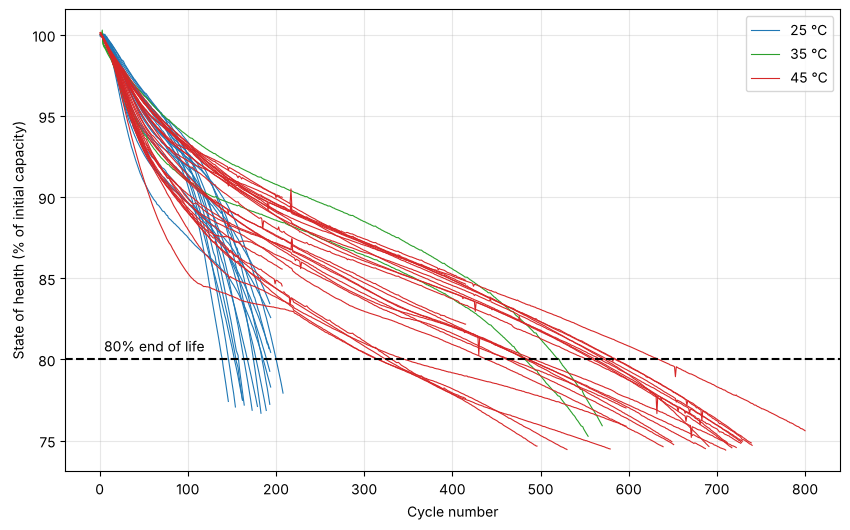

25 °C: 13 cells reached 80 %, median 168.0 cycles
35 °C: 2 cells reached 80 %, median 502.5 cycles
45 °C: 21 cells reached 80 %, median 487.0 cycles


In [10]:
# Report Figure 2: capacity fade of the 0.5C-charged cells at 25, 35 and 45 °C. Only 0.5C cells are
# used so that temperature is the only difference between groups. SoH is measured relative to each
# cell's own starting capacity (median of its first 3 cycles), so every line starts at 100 %. For each
# cell we also record the first cycle where SoH drops below 80 % (end of life), using the median of a
# 5-cycle window so a single bad cycle is ignored, and report the median cycles to 80 % per temperature.

colours = {25: 'tab:blue', 35: 'tab:green', 45: 'tab:red'}
cycles_to_80 = {25: [], 35: [], 45: []}

plt.figure(figsize=(10, 6))
for temp in [25, 35, 45]:
    cells = data[(data['temperature_c'] == temp) & (data['planned_charge_c_rate'] == 0.5)]
    first_line = True
    for cell_name in cells['cell'].unique():
        c = cells[cells['cell'] == cell_name].sort_values('sequence')
        cycle_numbers = c['sequence'].tolist()
        capacity = c['capacity_ah'].tolist()

        start = np.median(capacity[:3])
        soh = []
        for q in capacity:
            soh.append(100 * q / start)

        if first_line:
            plt.plot(cycle_numbers, soh, color=colours[temp], linewidth=0.8, label=str(temp) + ' °C')
            first_line = False
        else:
            plt.plot(cycle_numbers, soh, color=colours[temp], linewidth=0.8)

        for i in range(len(soh)):
            window = soh[max(0, i - 2): i + 3]
            if np.median(window) < 80:
                cycles_to_80[temp].append(cycle_numbers[i])
                break

plt.axhline(80, color='black', linestyle='--')
plt.text(5, 80.5, '80% end of life')
plt.xlabel('Cycle number')
plt.ylabel('State of health (% of initial capacity)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for temp in [25, 35, 45]:
    print(temp, '°C:', len(cycles_to_80[temp]), 'cells reached 80 %, median',
          np.median(cycles_to_80[temp]), 'cycles')

Cells at 25 °C were worn to 80 % SoH roughly three times sooner than those at 35 °C and 45 °C. The 45 °C cells initially lost capacity the fastest, declining steadily, whereas the 25 °C cells show a "knee" shape after around 100 cycles.

At 25 °C, 7/19/9 cells used 0.25/0.5/1C charging, while all the target cells used 0.5C, and all cells discharged at 1C. The transfer tests in Section 6 therefore change the mix of charging conditions as well as the temperature.

## 4. Model training

Capacity is a continuous number, so this is regression rather than classification, and we measure the prediction error rather than classification accuracy. All models use the same data and tests.

Every model is a pipeline: mean imputation, removal of inputs that are constant in the training data, StandardScaler, then the model. Imputation and scaling are fitted on the training data only. At 25 °C the temperature and discharge rate are constant, so removing them leaves 22 features.

The eight model families (report Table 2):
- Mean baseline and Ridge: simple reference and straight-line relationships
- RBF SVR: learns smooth, curved relationships
- Random forest and Extra trees: combine many decision trees
- Histogram boosting: adds trees to correct previous errors
- Small and large MLP (64–32 and 256–128–64 units): check whether a larger network helps

In [11]:
# Set-up for modelling. Models are trained and tested on the 25 °C cells first. Every model is a
# pipeline: fill missing values, remove inputs that never change in the training data (at 25 °C these
# are temperature and discharge rate), standardise the inputs, then fit the model. The two MLPs also
# standardise the target. cell_errors gives the MAE of each cell separately, so every battery counts
# equally (cell-macro MAE). earliest takes the earliest share of each cell's cycles, used later for
# learning curves and donor data.

source = data[data['temperature_c'] == 25]

constant_columns = []
for f in FEATURES:
    if source[f].nunique() == 1:
        constant_columns.append(f)
print('Constant columns at 25 °C:', constant_columns)

MODEL_NAMES = ['Mean baseline', 'Ridge', 'SVR', 'Random forest', 'Extra trees',
               'Hist. boosting', 'Small MLP', 'Large MLP']


def make_model(name, drop_constant=True):
    models = {
        'Mean baseline': DummyRegressor(),
        'Ridge': Ridge(alpha=1.0),
        'SVR': SVR(C=10, epsilon=0.02),
        'Random forest': RandomForestRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=42),
        'Extra trees': ExtraTreesRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=42),
        'Hist. boosting': HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                                        l2_regularization=1, early_stopping=False, random_state=42),
        'Small MLP': MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=256, max_iter=150,
                                  early_stopping=True, n_iter_no_change=10, random_state=42),
        'Large MLP': MLPRegressor(hidden_layer_sizes=(256, 128, 64), alpha=1e-3, batch_size=256, max_iter=150,
                                  early_stopping=True, n_iter_no_change=10, random_state=42),
    }
    if drop_constant:
        pipe = make_pipeline(SimpleImputer(), VarianceThreshold(0.0), StandardScaler(), models[name])
    else:
        pipe = make_pipeline(SimpleImputer(), StandardScaler(), models[name])

    if 'MLP' in name:
        pipe = TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())
    return pipe


def cell_errors(df, pred):
    errors = (df['capacity_ah'] - pred).abs()
    return errors.groupby(df['cell']).mean()


def earliest(df, frac, minimum=0):
    parts = []
    for cell in sorted(df['cell'].unique()):
        c = df[df['cell'] == cell].sort_values('sequence')
        n = max(int(np.ceil(frac * len(c))), minimum)
        parts.append(c.head(n))
    return pd.concat(parts)

Constant columns at 25 °C: ['ambient_c', 'planned_discharge_c_rate']


At 25 °C, each of the 35 cells is tested once after being excluded from training: the model is trained on the other 34 cells and predicts every cycle of the held-out cell. This reduces the risk of reporting good results merely because related cycles from the same battery appeared in both training and testing.

In [12]:
# Leave-one-cell-out at 25 °C: for each model, hide one cell, train on the other 34,
# predict the hidden cell, and repeat for all 35 cells.

loco_pred = {}
for name in MODEL_NAMES:
    pred = pd.Series(0.0, index=source.index)          # one slot per cycle, filled below
    for cell in sorted(source['cell'].unique()):
        train = source[source['cell'] != cell]
        test = source[source['cell'] == cell]

        model = make_model(name)
        model.fit(train[FEATURES], train['capacity_ah'])
        pred[test.index] = model.predict(test[FEATURES])

    loco_pred[name] = pred
    print(name, 'done')

Mean baseline done


Ridge done


SVR done


Random forest done


Extra trees done


Hist. boosting done


Small MLP done


Large MLP done


## 5. Evaluation and results

MAE is the average size of an error, ignoring whether the estimate is too high or low. It is calculated for each cell and then averaged across cells equally (cell-macro MAE), so each battery has equal weight even when it contributes many more cycles. SoH error is the MAE relative to 3.5 Ah. The worst cell and the number of cells meeting 0.05 Ah show whether a good average hides harder cells, and R² is included as an extra measure.

In [13]:
# Evaluation: compare each model's leave-one-cell-out predictions with the true capacities.

baseline_mae = cell_errors(source, loco_pred['Mean baseline']).mean()

rows = []
for name in MODEL_NAMES:
    pred = loco_pred[name]
    per_cell = cell_errors(source, pred)      # one MAE per battery
    mae = per_cell.mean()

    rows.append({'Model': name,
                 'MAE (Ah)': mae,
                 'SoH error (% pts)': 100 * mae / NOMINAL_AH,
                 'Worst cell (Ah)': per_cell.max(),
                 'Cells <= 0.05 Ah': (per_cell <= TARGET_AH).sum(),
                 'R2': r2_score(source['capacity_ah'], pred),
                 'Better than baseline (%)': 100 * (1 - mae / baseline_mae)})

results = pd.DataFrame(rows).set_index('Model').sort_values('MAE (Ah)')
results.round(4)

,MAE (Ah),SoH error (% pts),Worst cell (Ah),Cells <= 0.05 Ah,R2,Better than baseline (%)
Model,,,,,,
Small MLP,0.0454,1.2979,0.1660,26,0.8991,71.5346
SVR,0.0469,1.3398,0.1216,23,0.9048,70.6159
Large MLP,0.0472,1.3481,0.1644,24,0.8988,70.4333
Hist. boosting,0.0506,1.4457,0.1826,20,0.8998,68.2936
Extra trees,0.0541,1.5448,0.1773,21,0.8874,66.1208
Random forest,0.0551,1.5753,0.1717,19,0.8826,65.4499
Ridge,0.0591,1.6898,0.1661,18,0.8235,62.9392
Mean baseline,0.1596,4.5596,0.2032,0,-0.0101,0.0000


All models perform better than the mean baseline. The small MLP, SVR and large MLP meet the 0.05 Ah target with errors of around 1.3 % SoH, and lie very close to each other, showing that no model is clearly the best. This suggests that the relaxation features matter more than the choice of model.

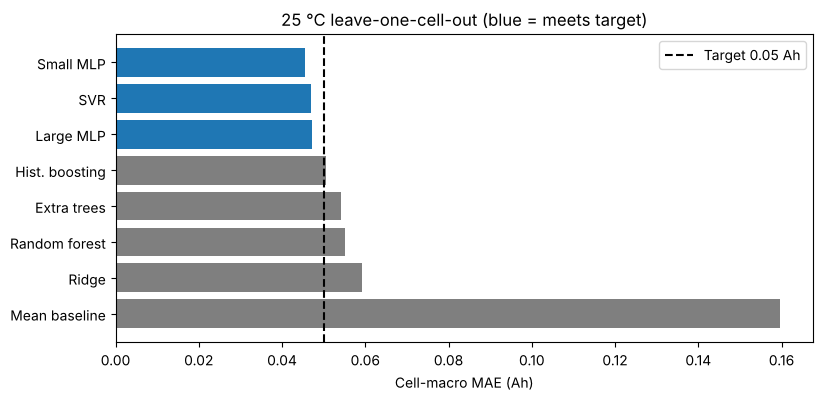

In [14]:
# Bar chart of 25 °C results: blue = meets the 0.05 Ah target, grey = does not.
colours = []
for mae in results['MAE (Ah)']:
    if mae <= TARGET_AH:
        colours.append('tab:blue')
    else:
        colours.append('tab:gray')

plt.figure(figsize=(9, 4))
plt.barh(results.index, results['MAE (Ah)'], color=colours)
plt.axvline(TARGET_AH, color='black', linestyle='--', label='Target 0.05 Ah')
plt.gca().invert_yaxis()
plt.xlabel('Cell-macro MAE (Ah)')
plt.title('25 °C leave-one-cell-out (blue = meets target)')
plt.legend()
plt.show()

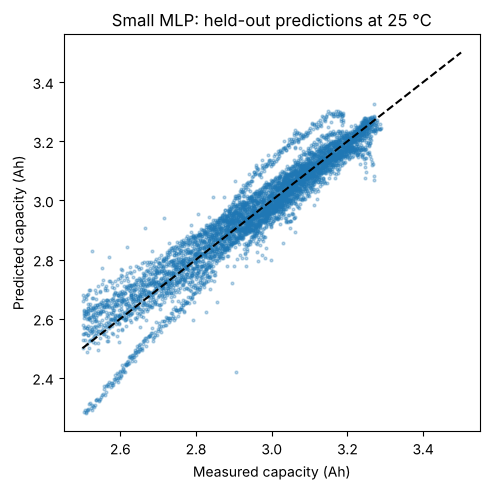

In [15]:
# predicted against measured capacity for the best model; the dashed line is a perfect prediction
best = results.index[0]
plt.figure(figsize=(5, 5))
plt.scatter(source['capacity_ah'], loco_pred[best], s=4, alpha=0.3)
plt.plot([2.5, 3.5], [2.5, 3.5], 'k--')
plt.xlabel('Measured capacity (Ah)')
plt.ylabel('Predicted capacity (Ah)')
plt.title(best + ': held-out predictions at 25 °C')
plt.tight_layout()
plt.show()

Training diagnostics (report Figure 1): each MLP is trained on the earliest 10, 25, 50 and 100 % of source cycles from 34 cells, and checked on one separate validation cell. The gap between training and validation error suggests that extra model complexity does not always help a new battery, but it does not prove that a network overfits. These diagnostic curves are not the final model ranking.

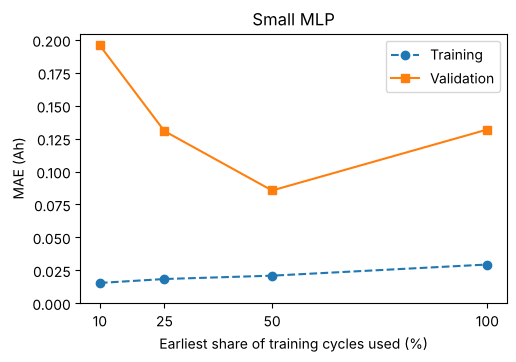

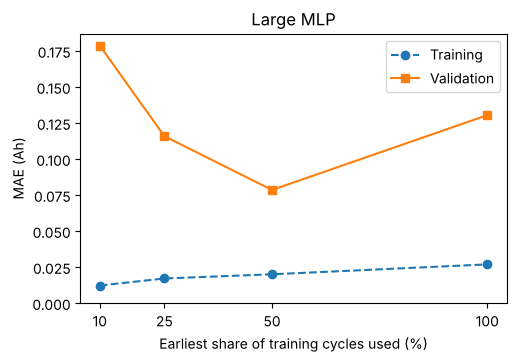

In [16]:
# Learning curves (report Figure 1): train each MLP on the earliest 10/25/50/100 % of cycles from 34 cells
# and compare the error on the training data with the error on one separate validation cell.
# A large gap between the two suggests the model fits the training cells better than it generalises.

cells_25 = sorted(source['cell'].unique())
valid = source[source['cell'] == cells_25[-1]]       # validation cell
pool = source[source['cell'] != cells_25[-1]]        # the other 34 cells
percentages = [10, 25, 50, 100]

for name in ['Small MLP', 'Large MLP']:
    train_mae = []
    valid_mae = []
    for p in percentages:
        train = earliest(pool, p / 100, minimum=2)
        model = make_model(name)
        model.fit(train[FEATURES], train['capacity_ah'])
        train_mae.append(cell_errors(train, model.predict(train[FEATURES])).mean())
        valid_mae.append(cell_errors(valid, model.predict(valid[FEATURES])).mean())

    plt.figure(figsize=(5.5, 3.5))
    plt.plot(percentages, train_mae, 'o--', label='Training')
    plt.plot(percentages, valid_mae, 's-', label='Validation')
    plt.xticks(percentages)
    plt.ylim(bottom=0)
    plt.xlabel('Earliest share of training cycles used (%)')
    plt.ylabel('MAE (Ah)')
    plt.title(name)
    plt.legend()
    plt.show()

## 6. Temperature transfer

First, each model is trained on all 25 °C cells and tested on every 35 °C and 45 °C cell, with no data from those temperatures. Each model is trained twice: with all 24 inputs (original) and with the constant inputs removed. In the original version the temperature input was always 25 in training, so a test value of 45 is far outside anything the model has seen.

In [17]:
# Zero-data transfer: train each model on all 25 °C cells, then predict the 35 °C and 45 °C cells
# This is one of our main objectives: how models trained at room temperature adapt to other temperatures,
# with no data from those temperatures. Each model is trained twice: with all inputs (Original)
# and with the always-constant inputs removed.

targets = {35: data[data['temperature_c'] == 35], 45: data[data['temperature_c'] == 45]}

rows = []
for name in MODEL_NAMES:
    row = {'Model': name}
    for drop in [False, True]:
        model = make_model(name, drop_constant=drop)
        model.fit(source[FEATURES], source['capacity_ah'])

        if drop:
            version = 'removed'
        else:
            version = 'original'
        for temp in [35, 45]:
            target = targets[temp]
            row[str(temp) + ' °C ' + version] = cell_errors(target, model.predict(target[FEATURES])).mean()
    rows.append(row)

zero = pd.DataFrame(rows).set_index('Model')
zero.round(4)

,35 °C original,45 °C original,35 °C removed,45 °C removed
Model,,,,
Mean baseline,0.1985,0.1851,0.1985,0.1851
Ridge,0.0598,0.0864,0.0598,0.0864
SVR,0.4517,0.3257,0.0895,0.1282
Random forest,0.0649,0.1083,0.0641,0.1086
Extra trees,0.0656,0.1092,0.0679,0.1129
Hist. boosting,0.0552,0.0840,0.0552,0.0840
Small MLP,0.0852,0.0986,0.0555,0.0852
Large MLP,0.0681,0.1061,0.0763,0.0986


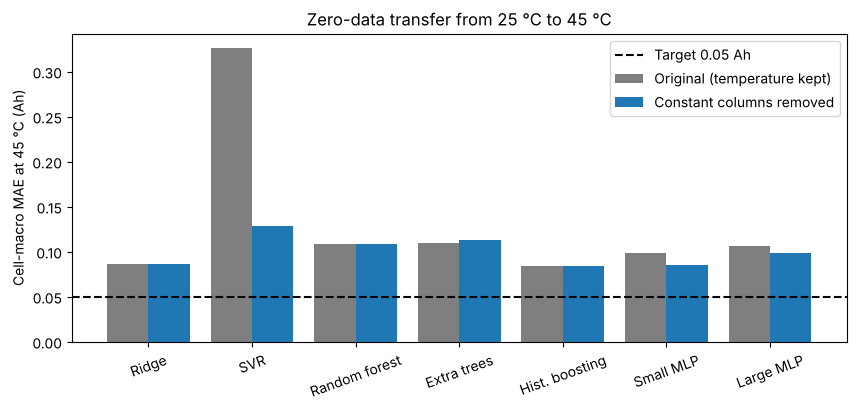

In [18]:
# every bar is above the target, so no model adapts to 45 °C without local data. SVR's grey bar is much taller than its blue one, 
# showing the constant-temperature problem. Tree models' bars are about equal.

z45 = zero.loc[MODEL_NAMES[1:]]               # leaving out the mean baseline because its bar is too tall and makes the chart hard to read
x = np.arange(len(z45))                       # bar positions 0, 1, 2 and so on

plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, z45['45 °C original'], width=0.4, color='tab:gray', label='Original (temperature kept)')
plt.bar(x + 0.2, z45['45 °C removed'], width=0.4, color='tab:blue', label='Constant columns removed')
plt.axhline(TARGET_AH, color='black', linestyle='--', label='Target 0.05 Ah')
plt.xticks(x, z45.index, rotation=20)
plt.ylabel('Cell-macro MAE at 45 °C (Ah)')
plt.title('Zero-data transfer from 25 °C to 45 °C')
plt.legend()
plt.show()

Using the 25 °C data alone, no model met the 0.05 Ah target at 35 °C or 45 °C. Removing the two constant inputs was essential for SVR, whose error dropped sharply, whereas the tree models were unaffected.

The check below predicts the 45 °C cells twice, once with their real temperature and once with the temperature set to 25, to see which models react to an unseen temperature value.

In [19]:
# What-if test: predict the 45 °C cells twice, once with their real temperature (45) and once with
# temperature set to 25. Everything else is the same, so any difference comes from temperature alone.
test = targets[45]
test_as_25 = test[FEATURES].copy()
test_as_25['ambient_c'] = 25

for name in ['SVR', 'Hist. boosting', 'Small MLP']:
    model = make_model(name, drop_constant=False)
    model.fit(source[FEATURES], source['capacity_ah'])

    difference = np.abs(model.predict(test[FEATURES]) - model.predict(test_as_25)).mean()
    print(name, ': prediction change from temperature alone =', round(difference, 4), 'Ah')

SVR : prediction change from temperature alone = 0.3304 Ah


Hist. boosting : prediction change from temperature alone = 0.0 Ah


Small MLP : prediction change from temperature alone = 0.0 Ah


SVR reacts strongly to the unseen temperature, and the tree model does not react at all, because a tree only splits on inputs that varied in training. The scikit-learn MLP used here also barely reacts, because its L2 penalty shrinks the weights on an input that never changed. The PyTorch MLPs in our full study kept those weights and were strongly affected (report Section 6.3). Either way, inputs that are constant within the training set should be removed.

Next, donor data is added. For transfer, training combines all 25 °C source data with the earliest 0, 1, 5, 10, 25, 50 or 100 % of cycles from each donor cell at the target temperature, rounded up. The test cell supplies no training labels. Each 35 °C test cell has two donor cells. In the full study each 45 °C test cell had 27 donors; here the 45 °C cells are tested in four groups of seven (21 donors each), using histogram boosting and the small MLP.

In [20]:
# Donor-data experiment: for each test cell at 35 °C or 45 °C, train on all 25 °C cells plus the earliest
# X % of cycles from the other cells at that temperature, then measure the error on the test cells.
# Test cells never supply training data. At 45 °C the cells are tested in 4 groups of 7.

donor_percentages = [0, 1, 5, 10, 25, 50, 100]
rows = []

for temp in [35, 45]:
    target = targets[temp]
    if temp == 35:
        n_groups = 3
    else:
        n_groups = 4
    splits = GroupKFold(n_splits=n_groups).split(target, groups=target['cell'])

    for donor_index, test_index in splits:
        test = target.iloc[test_index]
        donors = target.iloc[donor_index]

        for p in donor_percentages:
            donor_rows = earliest(donors, p / 100)
            train = pd.concat([source, donor_rows])

            for name in ['Hist. boosting', 'Small MLP']:
                model = make_model(name)
                model.fit(train[FEATURES], train['capacity_ah'])
                errors = cell_errors(test, model.predict(test[FEATURES]))

                for cell in errors.index:
                    rows.append({'Temperature': temp, 'Model': name, 'Donor %': p,
                                 'Donor cycles': len(donor_rows), 'Cell': cell, 'MAE': errors[cell]})
    print(temp, '°C done')

donor = pd.DataFrame(rows)
donor_summary = donor.groupby(['Temperature', 'Model', 'Donor %'])['MAE'].mean().unstack()
donor_summary.round(4)

35 °C done


45 °C done


Donor %                        0       1       5       10      25      50   \
Temperature Model                                                            
35          Hist. boosting  0.0552  0.0530  0.0509  0.0537  0.0510  0.0447   
            Small MLP       0.0555  0.2500  0.1909  0.1071  0.0851  0.0387   
45          Hist. boosting  0.0840  0.1115  0.0976  0.0701  0.0346  0.0269   
            Small MLP       0.0852  0.2377  0.0887  0.0978  0.0404  0.0431   

Donor %                        100  
Temperature Model                   
35          Hist. boosting  0.0329  
            Small MLP       0.0329  
45          Hist. boosting  0.0189  
            Small MLP       0.0187

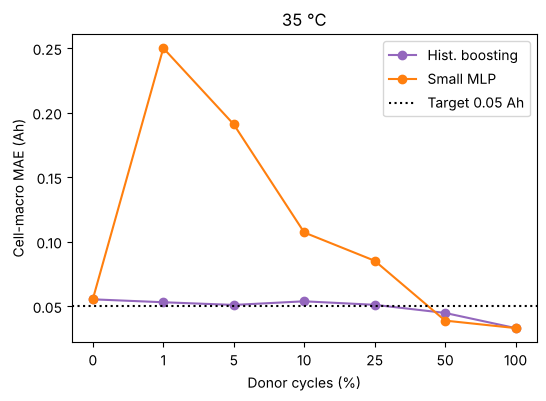

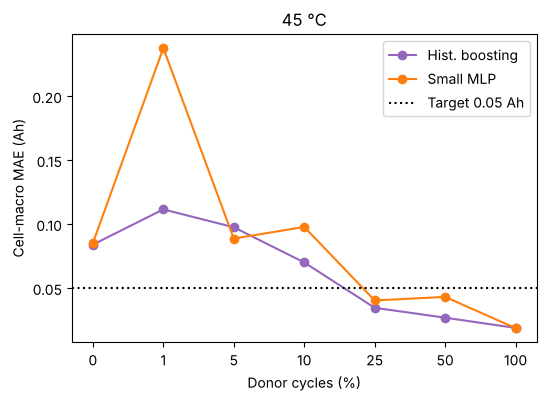

In [21]:
# Error on the held-out target cells as donor cycles are added (report Figure 3)
colours = {'Hist. boosting': 'tab:purple', 'Small MLP': 'tab:orange'}

for temp in [35, 45]:
    plt.figure(figsize=(6, 4))
    for name in ['Hist. boosting', 'Small MLP']:
        y = donor_summary.loc[(temp, name)]
        plt.plot(range(len(donor_percentages)), y.values, 'o-', color=colours[name], label=name)
    plt.axhline(TARGET_AH, color='black', linestyle=':', label='Target 0.05 Ah')
    plt.xticks(range(len(donor_percentages)), donor_percentages)
    plt.xlabel('Donor cycles (%)')
    plt.ylabel('Cell-macro MAE (Ah)')
    plt.title(str(temp) + ' °C')
    plt.legend()
    plt.show()

Cycles from other cells at the target temperature were required to reach the target. Small donor percentages are not always helpful: 1 % raised the small MLP's error because the earliest cycles describe new cells. The same percentage also requires very different numbers of measured cycles at 35 °C and 45 °C:

In [22]:
# number of donor cycles used at each donor percentage
donor.groupby(['Temperature', 'Donor %'])['Donor cycles'].agg(['min', 'max']).unstack(0)

min          max       
Temperature   35     45    35     45
Donor %                             
0              0      0     0      0
1              7    124    12    126
5             29    594    55    600
10            58   1183   109   1193
25           141   2953   271   2976
50           282   5897   541   5943
100          563  11788  1081  11881

## 7. Feature importance

The report uses SHAP, which splits each prediction into the contributions from each input. This notebook uses permutation importance, a simpler method that answers a similar question: each input is shuffled in turn, and a large increase in error means the model relies on that input. Models are trained on 28 of the 25 °C cells and checked on the other 7. Because the voltages are correlated with each other, they read as one group rather than independent factors, and importance shows reliance, not cause.

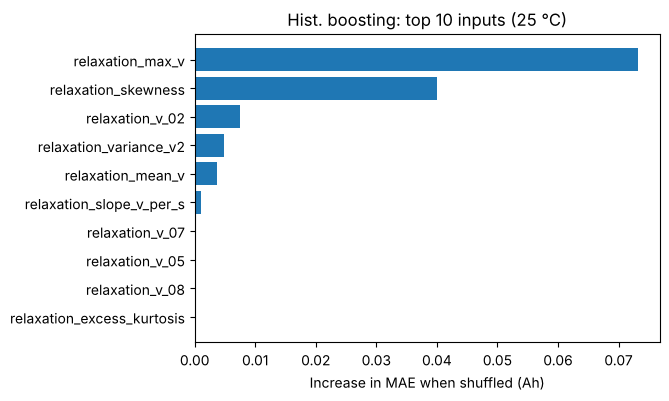

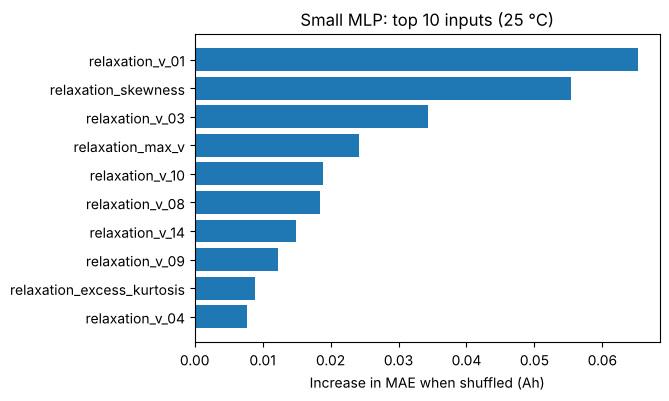

In [23]:
# Permutation importance: shuffle one input at a time and measure how much the error grows on 7 unseen
# 25 °C cells. A large increase means the model relies on that input.

split = GroupShuffleSplit(n_splits=1, test_size=7, random_state=42)
train_index, test_index = next(split.split(source, groups=source['cell']))
train = source.iloc[train_index]
test = source.iloc[test_index]

for name in ['Hist. boosting', 'Small MLP']:
    model = make_model(name)
    model.fit(train[FEATURES], train['capacity_ah'])
    result = permutation_importance(model, test[FEATURES], test['capacity_ah'],
                                    scoring='neg_mean_absolute_error', n_repeats=5, random_state=42)

    importance = pd.Series(result.importances_mean, index=FEATURES)
    top10 = importance.sort_values().tail(10)

    plt.figure(figsize=(6, 4))
    plt.barh(top10.index, top10.values)
    plt.xlabel('Increase in MAE when shuffled (Ah)')
    plt.title(name + ': top 10 inputs (25 °C)')
    plt.show()

As in the report's SHAP analysis, the models rely mainly on the relaxation skewness, the early relaxation voltages and the maximum relaxation voltage.

## Summary

- At 25 °C, the small MLP, SVR and large MLP meet the 0.05 Ah target (about 1.3 % SoH) on unseen cells and beat the mean baseline by about 70 %. No model is clearly the best.
- Averages hide harder cells: some individual cells miss the target.
- Using the 25 °C data alone, no model met the target at 35 °C or 45 °C.
- Inputs that never varied in training should be removed; SVR was strongly affected by the unseen temperature, while tree models were not.
- Adding early cycles from other cells at the target temperature brought the error below the target, while very small amounts (1 %) made it worse.

Limitations (report Section 6.5): only three cells at 35 °C, charge rate mixed with temperature, cycles only between 71 % and 100 % SoH, no cold data, and no uncertainty ranges. This notebook also uses simplified settings, so its numbers differ slightly from the report, which comes from the full study scripts.